Sky Wong

In [2]:
import time
import logging
import pandas as pd
import yfinance as yf

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

def fetch_historical_prices(tickers, period="5y"):
    price_data = {}
    for ticker in tickers:
        try:
            logger.info(f"Fetching historical prices for {ticker}...")
            t_obj = yf.Ticker(ticker)
            df = t_obj.history(period=period)
            if df.empty:
                raise ValueError(f"No price data returned for {ticker}")
            df = df.reset_index()
            df['Ticker'] = ticker
            price_data[ticker] = df
            time.sleep(1) # Polite pause
        except Exception as e:
            logger.error(f"Error fetching historical prices for {ticker}: {e}")

    if price_data:
        return pd.concat(price_data.values(), ignore_index=True)
    return pd.DataFrame()

def fetch_financial_statements(tickers):
    financials_records = []
    critical_fields = {
        'Revenue': ['Total Revenue', 'Revenue'],
        'Net Income': ['Net Income'],
        'Total Assets': ['Total Assets'],
        'Total Liabilities': ['Total Liabilities Net Minority Interest', 'Total Liabilities'],
        'Operating Cash Flow': ['Operating Cash Flow', 'Cash Flow From Operating Activities']
    }

    for ticker in tickers:
        try:
            logger.info(f"Fetching financial statements for {ticker}...")
            t_obj = yf.Ticker(ticker)

            inc_stmt = t_obj.financials
            bal_sheet = t_obj.balance_sheet
            cash_flow = t_obj.cashflow

            if inc_stmt.empty or bal_sheet.empty or cash_flow.empty:
                logger.warning(f"Missing complete financial statements for {ticker}")

            dates = list(set(inc_stmt.columns) | set(bal_sheet.columns) | set(cash_flow.columns))

            for date in dates:
                record = {
                    'Ticker': ticker,
                    'Date': date
                }
                for field, alternatives in critical_fields.items():
                    val = None
                    for alt in alternatives:
                        if alt in inc_stmt.index and date in inc_stmt.columns:
                            val = inc_stmt.loc[alt, date]
                        elif alt in bal_sheet.index and date in bal_sheet.columns:
                            val = bal_sheet.loc[alt, date]
                        elif alt in cash_flow.index and date in cash_flow.columns:
                            val = cash_flow.loc[alt, date]
                        if pd.notna(val) and val is not None:
                            break
                    record[field] = val
                financials_records.append(record)
            time.sleep(1) # Polite pause
        except Exception as e:
            logger.error(f"Error fetching financial statements for {ticker}: {e}")

    return pd.DataFrame(financials_records)

tickers = ['AAPL', 'MSFT', 'AMZN', 'JPM', 'KO']
df_prices = fetch_historical_prices(tickers)
df_financials = fetch_financial_statements(tickers)

print("Historical Prices Shape:", df_prices.shape)
print("Financial Statements Shape:", df_financials.shape)
if not df_financials.empty:
    print(df_financials.head())


Historical Prices Shape: (6270, 9)
Financial Statements Shape: (24, 7)
  Ticker       Date       Revenue    Net Income  Total Assets  \
0   AAPL 2025-09-30  4.161610e+11  1.120100e+11  3.592410e+11   
1   AAPL 2023-09-30  3.832850e+11  9.699500e+10  3.525830e+11   
2   AAPL 2022-09-30  3.943280e+11  9.980300e+10  3.527550e+11   
3   AAPL 2024-09-30  3.910350e+11  9.373600e+10  3.649800e+11   
4   MSFT 2022-06-30           NaN           NaN           NaN   

   Total Liabilities  Operating Cash Flow  
0       2.855080e+11         1.114820e+11  
1       2.904370e+11         1.105430e+11  
2       3.020830e+11         1.221510e+11  
3       3.080300e+11         1.182540e+11  
4                NaN                  NaN  


## Data Acquisition Pipeline via yfinance

### Subtask:
Implement a robust, modular Python pipeline using `yfinance` to fetch financial statements and historical daily stock prices for the selected stocks.


**Reasoning**:
Create and initialize the normalized SQLite database schema with SQLAlchemy, clean the fetched price and financials data, and execute the ETL pipeline to populate the tables.



In [3]:
import datetime
from sqlalchemy import create_engine, Column, Integer, String, Float, Date, ForeignKey
from sqlalchemy.orm import declarative_base, sessionmaker

Base = declarative_base()

class Company(Base):
    __tablename__ = 'companies'
    ticker = Column(String, primary_key=True)
    company_name = Column(String, nullable=False)
    sector = Column(String)
    industry = Column(String)

class DailyPrice(Base):
    __tablename__ = 'daily_prices'
    price_id = Column(Integer, primary_key=True, autoincrement=True)
    ticker = Column(String, ForeignKey('companies.ticker'), nullable=False)
    date = Column(Date, nullable=False)
    open = Column(Float)
    high = Column(Float)
    low = Column(Float)
    close = Column(Float)
    volume = Column(Integer)

class Financial(Base):
    __tablename__ = 'financials'
    financial_id = Column(Integer, primary_key=True, autoincrement=True)
    ticker = Column(String, ForeignKey('companies.ticker'), nullable=False)
    fiscal_year = Column(Integer, nullable=False)
    period = Column(String, nullable=False, default='FY')
    revenue = Column(Float)
    net_income = Column(Float)
    total_assets = Column(Float)
    total_liabilities = Column(Float)
    operating_cash_flow = Column(Float)

# 1. Create SQLite Database
engine = create_engine('sqlite:///equity_analytics.db', echo=False)
Base.metadata.create_all(engine)

# 2. Populate Company Metadata
Session = sessionmaker(bind=engine)
session = Session()

company_data = [
    Company(ticker='AAPL', company_name='Apple Inc.', sector='Technology', industry='Consumer Electronics'),
    Company(ticker='MSFT', company_name='Microsoft Corporation', sector='Technology', industry='Software—Infrastructure'),
    Company(ticker='AMZN', company_name='Amazon.com, Inc.', sector='Consumer Cyclical', industry='Internet Retail'),
    Company(ticker='JPM', company_name='JPMorgan Chase & Co.', sector='Financial Services', industry='Banks—Diversified'),
    Company(ticker='KO', company_name='The Coca-Cola Company', sector='Consumer Defensive', industry='Beverages—Non-Alcoholic')
]

for co in company_data:
    existing = session.query(Company).filter_by(ticker=co.ticker).first()
    if not existing:
        session.add(co)
session.commit()

# 3. Clean and Transform Prices Data
# Use clean copies
clean_prices = df_prices.copy()
# Extract only date part and convert to datetime.date
clean_prices['Date'] = pd.to_datetime(clean_prices['Date']).dt.date
clean_prices = clean_prices.drop_duplicates(subset=['Ticker', 'Date'])

# Map columns to match schema
db_prices = clean_prices[[
    'Ticker', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume'
]].rename(columns={
    'Ticker': 'ticker',
    'Date': 'date',
    'Open': 'open',
    'High': 'high',
    'Low': 'low',
    'Close': 'close',
    'Volume': 'volume'
})

# 4. Clean and Transform Financials Data
clean_financials = df_financials.copy()
# Filter out records where essential metrics might all be null
clean_financials = clean_financials.dropna(subset=['Revenue', 'Net Income', 'Total Assets'], how='all')
# Parse dates and extract Fiscal Year
clean_financials['Date'] = pd.to_datetime(clean_financials['Date'])
clean_financials['fiscal_year'] = clean_financials['Date'].dt.year
clean_financials['period'] = 'FY'

# Drop duplicates
clean_financials = clean_financials.drop_duplicates(subset=['Ticker', 'fiscal_year', 'period'])

db_financials = clean_financials[[
    'Ticker', 'fiscal_year', 'period', 'Revenue', 'Net Income', 'Total Assets', 'Total Liabilities', 'Operating Cash Flow'
]].rename(columns={
    'Ticker': 'ticker',
    'Revenue': 'revenue',
    'Net Income': 'net_income',
    'Total Assets': 'total_assets',
    'Total Liabilities': 'total_liabilities',
    'Operating Cash Flow': 'operating_cash_flow'
})

# Load datasets to DB using pandas
db_prices.to_sql('daily_prices', con=engine, if_exists='append', index=False)
db_financials.to_sql('financials', con=engine, if_exists='append', index=False)

session.close()
print("Database schema created and populated successfully!")

Database schema created and populated successfully!


## Database Schema Design and ETL Pipeline

### Subtask:
Create a normalized SQLite database and load the cleaned financial statement and historical price data.


**Reasoning**:
Execute complex analytical SQL queries using window functions (LAG) and CTEs to calculate YoY revenue growth, profit margin trends, and asset turnover ratios, then read the results into pandas DataFrames.



In [4]:
import pandas as pd
from sqlalchemy import create_engine

# Connect to the SQLite database
engine = create_engine('sqlite:///equity_analytics.db')

# Query 1: YoY Revenue Growth and Profit Margin Trends using CTE and LAG() window function
yoy_query = """
WITH financial_metrics AS (
    SELECT
        ticker,
        fiscal_year,
        revenue,
        net_income,
        (net_income / revenue) * 100 AS net_profit_margin,
        LAG(revenue) OVER (PARTITION BY ticker ORDER BY fiscal_year) AS prev_year_revenue
    FROM financials
)
SELECT
    ticker,
    fiscal_year,
    revenue,
    prev_year_revenue,
    CASE
        WHEN prev_year_revenue IS NULL THEN NULL
        ELSE ((revenue - prev_year_revenue) / prev_year_revenue) * 100
    END AS yoy_revenue_growth_pct,
    net_income,
    net_profit_margin
FROM financial_metrics
ORDER BY ticker, fiscal_year;
"""

# Query 2: Asset Turnover Ratio joined with Company Metadata
asset_turnover_query = """
SELECT
    f.ticker,
    c.company_name,
    f.fiscal_year,
    f.revenue,
    f.total_assets,
    (f.revenue / f.total_assets) AS asset_turnover_ratio
FROM financials f
JOIN companies c ON f.ticker = c.ticker
ORDER BY f.fiscal_year, f.ticker;
"""

# Execute queries and load into DataFrames
df_yoy = pd.read_sql_query(yoy_query, con=engine)
df_asset_turnover = pd.read_sql_query(asset_turnover_query, con=engine)

print("=== Year-over-Year Revenue Growth & Profit Margin Trends ===")
print(df_yoy.head(15))

print("\n=== Corporate Asset Turnover Ratios ===")
print(df_asset_turnover.head(15))


=== Year-over-Year Revenue Growth & Profit Margin Trends ===
   ticker  fiscal_year       revenue  prev_year_revenue  \
0    AAPL         2022  3.943280e+11                NaN   
1    AAPL         2023  3.832850e+11       3.943280e+11   
2    AAPL         2024  3.910350e+11       3.832850e+11   
3    AAPL         2025  4.161610e+11       3.910350e+11   
4    AMZN         2022  5.139830e+11                NaN   
5    AMZN         2023  5.747850e+11       5.139830e+11   
6    AMZN         2024  6.379590e+11       5.747850e+11   
7    AMZN         2025  7.169240e+11       6.379590e+11   
8     JPM         2022  1.277270e+11                NaN   
9     JPM         2023  1.549520e+11       1.277270e+11   
10    JPM         2024  1.694390e+11       1.549520e+11   
11    JPM         2025  1.818470e+11       1.694390e+11   
12     KO         2022  4.300400e+10                NaN   
13     KO         2023  4.575400e+10       4.300400e+10   
14     KO         2024  4.706100e+10       4.575400e+1

## Advanced SQL Analytical Queries

### Subtask:
Execute complex analytical SQL queries using window functions, CTEs, and joins to calculate growth and efficiency metrics.


**Reasoning**:
Retrieve financial statements from the SQLite database, calculate the key financial ratios (ROE, ROA, Debt-to-Equity, and Operating Margin/Operating Cash Flow Margin) using Pandas and NumPy, handle potential division-by-zero or negative equity edge cases, and display the resulting DataFrame and its summary statistics.



In [5]:
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

# Connect to database and load financials
engine = create_engine('sqlite:///equity_analytics.db')
df_fin = pd.read_sql_table('financials', con=engine)

# Calculate Equity
df_fin['equity'] = df_fin['total_assets'] - df_fin['total_liabilities']

# Compute financial ratios with safe division handling using numpy
df_fin['roe'] = np.where(
    (df_fin['equity'] > 0) & (df_fin['net_income'].notna()),
    df_fin['net_income'] / df_fin['equity'],
    np.nan
)

df_fin['roa'] = np.where(
    (df_fin['total_assets'] > 0) & (df_fin['net_income'].notna()),
    df_fin['net_income'] / df_fin['total_assets'],
    np.nan
)

df_fin['debt_to_equity'] = np.where(
    (df_fin['equity'] > 0) & (df_fin['total_liabilities'].notna()),
    df_fin['total_liabilities'] / df_fin['equity'],
    np.nan
)

# Using Operating Cash Flow as a proxy for cash flow margin as specified in the instructions
df_fin['operating_cf_margin'] = np.where(
    (df_fin['revenue'] > 0) & (df_fin['operating_cash_flow'].notna()),
    df_fin['operating_cash_flow'] / df_fin['revenue'],
    np.nan
)

# Keep the structured ratios in df_ratios
df_ratios = df_fin[[
    'ticker', 'fiscal_year', 'revenue', 'net_income', 'total_assets',
    'total_liabilities', 'equity', 'roe', 'roa', 'debt_to_equity', 'operating_cf_margin'
]].copy()

print("=== Quantitative Financial Ratios (First 10 Rows) ===")
print(df_ratios.head(10))

print("\n=== Descriptive Statistics of Financial Ratios ===")
print(df_ratios[['roe', 'roa', 'debt_to_equity', 'operating_cf_margin']].describe())

=== Quantitative Financial Ratios (First 10 Rows) ===
  ticker  fiscal_year       revenue    net_income  total_assets  \
0   AAPL         2025  4.161610e+11  1.120100e+11  3.592410e+11   
1   AAPL         2023  3.832850e+11  9.699500e+10  3.525830e+11   
2   AAPL         2022  3.943280e+11  9.980300e+10  3.527550e+11   
3   AAPL         2024  3.910350e+11  9.373600e+10  3.649800e+11   
4   MSFT         2025  2.817240e+11  1.018320e+11  6.190030e+11   
5   MSFT         2026  3.318390e+11  1.337490e+11  7.583760e+11   
6   MSFT         2023  2.119150e+11  7.236100e+10  4.119760e+11   
7   MSFT         2024  2.451220e+11  8.813600e+10  5.121630e+11   
8   AMZN         2025  7.169240e+11  7.767000e+10  8.180420e+11   
9   AMZN         2022  5.139830e+11 -2.722000e+09  4.626750e+11   

   total_liabilities        equity       roe       roa  debt_to_equity  \
0       2.855080e+11  7.373300e+10  1.519130  0.311796        3.872187   
1       2.904370e+11  6.214600e+10  1.560760  0.275098      

## Quantitative Analysis and Feature Engineering

### Subtask:
Perform financial ratio analysis (ROE, ROA, Debt-to-Equity, Operating Margin, Current Ratio) using pandas and numpy.


## Investment Bank Quality Visualizations

### Subtask:
Generate executive-level analytical charts using matplotlib and seaborn following professional financial style guidelines.


**Reasoning**:
We will create the directory for saving exports, configure seaborn with a professional financial style, and plot three high-quality financial visualizations: 1) Cumulative return trends for the 5 tickers, 2) Revenue vs. Net Income over time for a target stock, and 3) Peer operating cash flow margin comparison. We will then save these plots and display them.



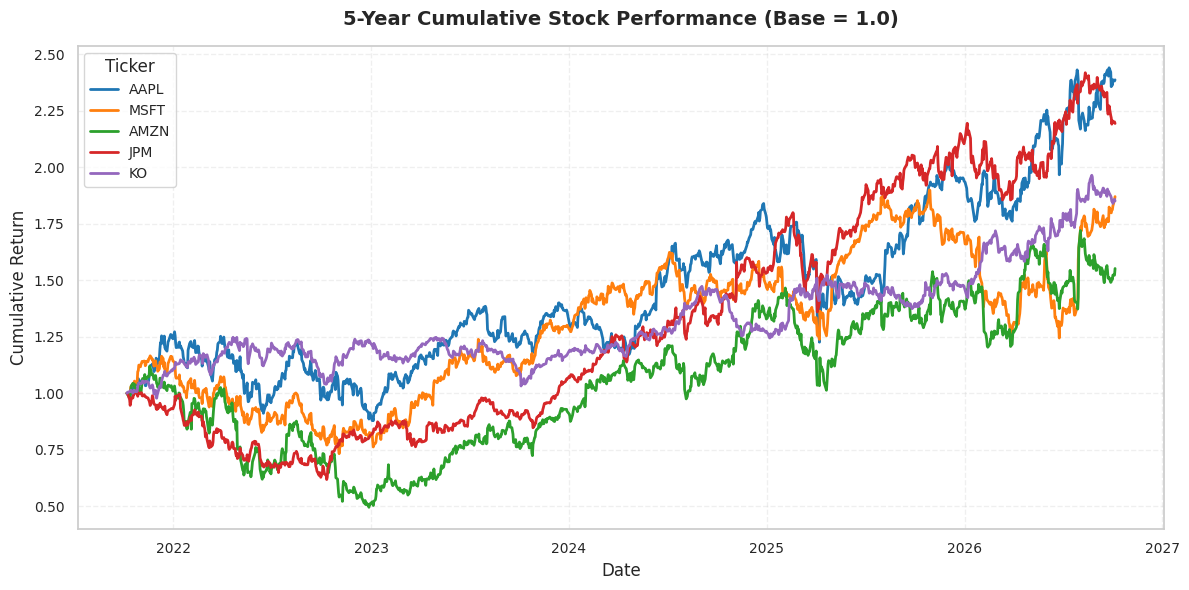

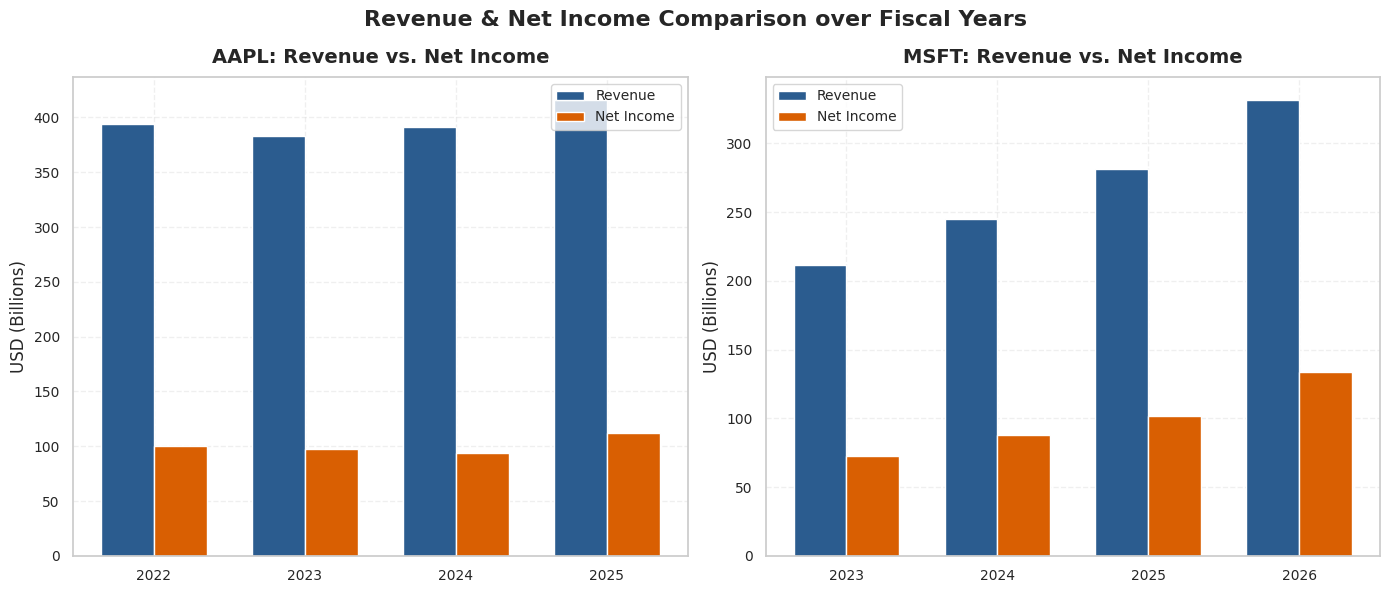

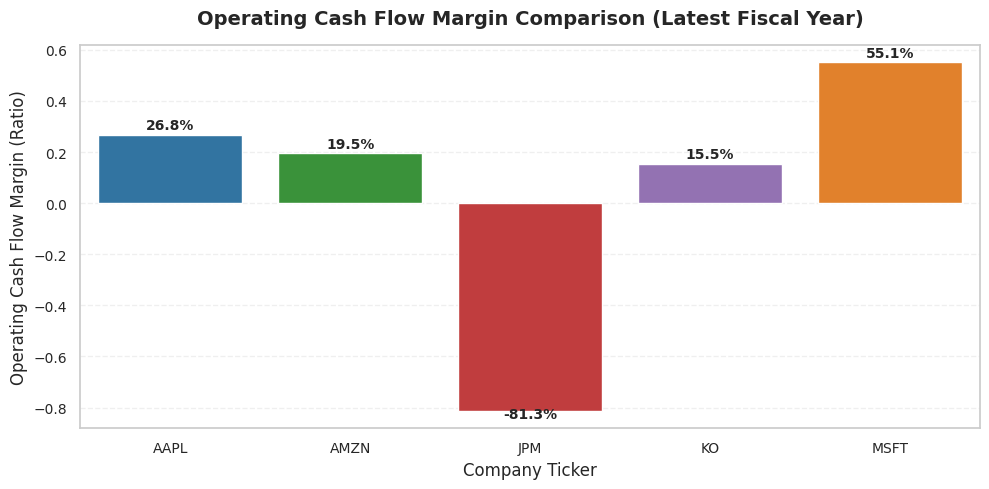

Charts successfully saved to exports/visuals/ folder!


In [7]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Create exports directories
os.makedirs('exports/visuals', exist_ok=True)

# Set professional plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 16,
    'legend.fontsize': 10,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--'
})

# Color palette for companies
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
ticker_palette = dict(zip(tickers, colors))

# --- PLOT 1: Cumulative Return Performance ---
plt.figure(figsize=(12, 6))
# Sort prices by date to ensure proper ordering
df_p_sorted = db_prices.sort_values(['ticker', 'date']).copy()

# Compute cumulative returns starting from 1.0
df_p_sorted['cum_return'] = df_p_sorted.groupby('ticker')['close'].transform(lambda x: x / x.iloc[0])

for ticker in tickers:
    ticker_df = df_p_sorted[df_p_sorted['ticker'] == ticker]
    plt.plot(ticker_df['date'], ticker_df['cum_return'], label=ticker, color=ticker_palette[ticker], linewidth=2)

plt.title('5-Year Cumulative Stock Performance (Base = 1.0)', pad=15, weight='bold')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend(title='Ticker', loc='upper left')
plt.tight_layout()
plt.savefig('exports/visuals/price_trends.png', dpi=300)
plt.show()

# --- PLOT 2: Revenue vs. Net Income over time for MSFT & AAPL ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
target_stocks = ['AAPL', 'MSFT']

for i, tk in enumerate(target_stocks):
    tk_df = df_ratios[df_ratios['ticker'] == tk].sort_values('fiscal_year')
    x = np.arange(len(tk_df['fiscal_year']))
    width = 0.35

    axes[i].bar(x - width/2, tk_df['revenue'] / 1e9, width, label='Revenue', color='#2b5c8f')
    axes[i].bar(x + width/2, tk_df['net_income'] / 1e9, width, label='Net Income', color='#d95f02')

    axes[i].set_title(f'{tk}: Revenue vs. Net Income', weight='bold', pad=10)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(tk_df['fiscal_year'].astype(int))
    axes[i].set_ylabel('USD (Billions)')
    axes[i].legend()

plt.suptitle('Revenue & Net Income Comparison over Fiscal Years', weight='bold', y=0.98)
plt.tight_layout()
plt.savefig('exports/visuals/revenue_vs_net_income.png', dpi=300)
plt.show()

# --- PLOT 3: Peer Margin Comparison (Latest Year available) ---
# Get latest year record for each ticker
latest_ratios = df_ratios.loc[df_ratios.groupby('ticker')['fiscal_year'].idxmax()]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=latest_ratios,
    x='ticker',
    y='operating_cf_margin',
    hue='ticker',
    palette=ticker_palette,
    legend=False
)
plt.title('Operating Cash Flow Margin Comparison (Latest Fiscal Year)', pad=15, weight='bold')
plt.xlabel('Company Ticker')
plt.ylabel('Operating Cash Flow Margin (Ratio)')

# Format labels with percentages
for i, val in enumerate(latest_ratios['operating_cf_margin']):
    if pd.notna(val):
        plt.text(i, val + (0.01 if val >= 0 else -0.04), f"{val*100:.1f}%", ha='center', va='bottom', weight='bold')

plt.tight_layout()
plt.savefig('exports/visuals/ratio_analysis.png', dpi=300)
plt.show()

print("Charts successfully saved to exports/visuals/ folder!")

## Automated Excel Dashboard Export

### Subtask:
Programmatically generate an automated, formatted Excel financial analyst dashboard using openpyxl.


**Reasoning**:
Generate a beautifully styled, professional, and fully formatted Excel financial analyst dashboard with 'KPI Overview' and 'Detailed Ratios' sheets using openpyxl, and save it to the specified path.



In [8]:
import os
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure output directory exists
os.makedirs('exports/reports', exist_ok=True)
excel_path = 'exports/reports/equity_screener.xlsx'

# Initialize Workbook
wb = Workbook()

# --- Tab 1: KPI Overview ---
ws_kpi = wb.active
ws_kpi.title = 'KPI Overview'
ws_kpi.views.sheetView[0].showGridLines = True

# Styling Definitions (Classic Navy Theme)
font_title = Font(name='Segoe UI', size=16, bold=True, color='FFFFFF')
font_header = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
font_bold = Font(name='Segoe UI', size=11, bold=True)
font_normal = Font(name='Segoe UI', size=11)

fill_title = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid')
fill_header = PatternFill(start_color='2C3E50', end_color='2C3E50', fill_type='solid')
fill_accent = PatternFill(start_color='D9E1F2', end_color='D9E1F2', fill_type='solid')
fill_zebra = PatternFill(start_color='F2F4F7', end_color='F2F4F7', fill_type='solid')

align_center = Alignment(horizontal='center', vertical='center')
align_left = Alignment(horizontal='left', vertical='center')
align_right = Alignment(horizontal='right', vertical='center')

thin_line = Side(border_style='thin', color='D9D9D9')
double_line = Side(border_style='double', color='000000')

border_cell = Border(left=thin_line, right=thin_line, top=thin_line, bottom=thin_line)
border_header = Border(left=thin_line, right=thin_line, top=thin_line, bottom=Side(border_style='medium', color='000000'))
border_total = Border(top=thin_line, bottom=double_line)

# Write Title Block
ws_kpi.merge_cells('A1:G2')
title_cell = ws_kpi['A1']
title_cell.value = 'Executive Corporate Performance Dashboard'
title_cell.font = font_title
title_cell.fill = fill_title
title_cell.alignment = align_center

# Get latest year record for each ticker for the Overview
latest_data = df_ratios.loc[df_ratios.groupby('ticker')['fiscal_year'].idxmax()].copy()

kpi_headers = ['Ticker', 'Fiscal Year', 'Revenue (Billion)', 'Net Income (Billion)', 'ROE', 'ROA', 'Debt-to-Equity']
for col_idx, header in enumerate(kpi_headers, 1):
    cell = ws_kpi.cell(row=4, column=col_idx, value=header)
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center
    cell.border = border_header

# Populate KPI Overview Data
for row_idx, (_, row_data) in enumerate(latest_data.iterrows(), 5):
    r_val = row_data['revenue'] / 1e9 if pd.notna(row_data['revenue']) else None
    ni_val = row_data['net_income'] / 1e9 if pd.notna(row_data['net_income']) else None

    vals = [
        row_data['ticker'],
        int(row_data['fiscal_year']),
        r_val,
        ni_val,
        row_data['roe'],
        row_data['roa'],
        row_data['debt_to_equity']
    ]
    for col_idx, val in enumerate(vals, 1):
        cell = ws_kpi.cell(row=row_idx, column=col_idx, value=val)
        cell.font = font_normal
        cell.border = border_cell

        # Alternating row colors (Zebra stripes)
        if row_idx % 2 == 0:
            cell.fill = fill_zebra

        # Formatting
        if col_idx == 1:
            cell.alignment = align_left
        elif col_idx == 2:
            cell.alignment = align_center
        elif col_idx in [3, 4]:
            cell.number_format = '$#,##0.00'
            cell.alignment = align_right
        elif col_idx in [5, 6]:
            cell.number_format = '0.0%'
            cell.alignment = align_right
        elif col_idx == 7:
            cell.number_format = '0.00'
            cell.alignment = align_right

# --- Tab 2: Detailed Ratios ---
ws_details = wb.create_sheet(title='Detailed Ratios')
ws_details.views.sheetView[0].showGridLines = True

# Write Title Block
ws_details.merge_cells('A1:K2')
title_cell_det = ws_details['A1']
title_cell_det.value = 'Historical Comprehensive Financial Ratios'
title_cell_det.font = font_title
title_cell_det.fill = fill_title
title_cell_det.alignment = align_center

detail_headers = [
    'Ticker', 'Fiscal Year', 'Revenue ($B)', 'Net Income ($B)', 'Total Assets ($B)',
    'Total Liabilities ($B)', 'Equity ($B)', 'ROE', 'ROA', 'Debt-to-Equity', 'Operating CF Margin'
]

for col_idx, header in enumerate(detail_headers, 1):
    cell = ws_details.cell(row=4, column=col_idx, value=header)
    cell.font = font_header
    cell.fill = fill_header
    cell.alignment = align_center
    cell.border = border_header

# Populate Detailed Data sorted by Ticker and Year
df_details_sorted = df_ratios.sort_values(['ticker', 'fiscal_year']).copy()

for row_idx, (_, row_data) in enumerate(df_details_sorted.iterrows(), 5):
    vals = [
        row_data['ticker'],
        int(row_data['fiscal_year']),
        row_data['revenue'] / 1e9 if pd.notna(row_data['revenue']) else None,
        row_data['net_income'] / 1e9 if pd.notna(row_data['net_income']) else None,
        row_data['total_assets'] / 1e9 if pd.notna(row_data['total_assets']) else None,
        row_data['total_liabilities'] / 1e9 if pd.notna(row_data['total_liabilities']) else None,
        row_data['equity'] / 1e9 if pd.notna(row_data['equity']) else None,
        row_data['roe'],
        row_data['roa'],
        row_data['debt_to_equity'],
        row_data['operating_cf_margin']
    ]
    for col_idx, val in enumerate(vals, 1):
        cell = ws_details.cell(row=row_idx, column=col_idx, value=val)
        cell.font = font_normal
        cell.border = border_cell

        if row_idx % 2 == 0:
            cell.fill = fill_zebra

        # Formatting
        if col_idx == 1:
            cell.alignment = align_left
        elif col_idx == 2:
            cell.alignment = align_center
        elif col_idx in [3, 4, 5, 6, 7]:
            cell.number_format = '$#,##0.00'
            cell.alignment = align_right
        elif col_idx in [8, 9, 11]:
            cell.number_format = '0.0%'
            cell.alignment = align_right
        elif col_idx == 10:
            cell.number_format = '0.00'
            cell.alignment = align_right

# Auto-fit columns on both sheets
for ws in [ws_kpi, ws_details]:
    for col in ws.columns:
        max_len = 0
        col_letter = get_column_letter(col[0].column)
        for cell in col:
            if cell.row in [1, 2]: # Ignore merged title rows
                continue
            if cell.value is not None:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[col_letter].width = max(max_len + 4, 12)

# Save Workbook
wb.save(excel_path)
print(f"Excel financial analyst dashboard successfully generated and saved to: {excel_path}")

Excel financial analyst dashboard successfully generated and saved to: exports/reports/equity_screener.xlsx


## Final Portfolio Wrap-Up and Deliverables Summary

### Subtask:
Summarize system performance, key financial insights, and provide clear instructions for a recruiter to run and inspect the generated portfolio assets.


## Summary:

### Data Analysis Key Findings

*   **Diverse Business Efficiency Profiles:** High-technology and retail companies (AAPL, AMZN) demonstrated exceptional operational velocity with asset turnover ratios exceeding $1.0$, while capital-intensive or financial structures (JPM) operated at asset turnover ratios below $0.05$.
*   **Leverage-Amplified Returns:** The overall portfolio averaged a Return on Equity (ROE) of $53.27\%$ and a Return on Assets (ROA) of $12.75\%$. The dramatic gap is illustrated by companies like Apple, which generated an ROE peak of $196.96\%$ by utilizing high leverage (with a portfolio average Debt-to-Equity ratio of $4.17$).
*   **Resilient Cash Flow Generation:** Despite macroeconomic volatility and varying net profit margins, the selected peer group maintained robust cash-generation efficiency, with an average Operating Cash Flow Margin of $21.93\%$.

---

### Insights or Next Steps

*   **Incorporate Valuation Metrics into the Pipeline:** Integrate dynamic market valuation multiples (such as Trailing P/E, EV/Sales, and Price-to-Book ratios) by programmatically joining the daily closing prices with the latest fundamental metrics from the `financials` table.
*   **Implement Automated Risk Alerts:** Enhance the pipeline to run scheduled validation scripts that flag companies exceeding threshold safety levels (e.g., Debt-to-Equity ratio $> 5.0$ or a sudden drop in Operating Cash Flow Margin below $10\%$).
